# Plot the steady state spectrum for single configuration

In [2]:
import numpy as np
import os
import astropy.units as u
import astropy.constants as const
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import h5py

import flash_amr_tools

from bowshock_config import bowshock_config, bow_shock_labels
from utils import get_file_at_time, get_shock_mask

import steady state spectrum properties

In [3]:
flash_output_dir = "/home/watanabe/Projects/meerkat_bowshocks/outputs"
fig_dir = "/home/watanabe/Projects/meerkat_bowshocks/figures"
data_dir = "/home/watanabe/Projects/meerkat_bowshocks/crbowshock_analysis_tools/data"


with h5py.File(f"{data_dir}/steady_state_spectrum_thr.h5", "r") as f:
    log10_R0_grid = f["log10_R0_grid"][()]
    log10_vel_grid = f["log10_vel_grid"][()]
    log10_kappa10_grid = f["log10_kappa10_grid"][()]
    log10_dens_grid = f["log10_dens_grid"][()]
    alpha_inj_grid = f["alpha_inj_grid"][()]
    log10_mom_grid = f["log10_pprot_grid"][()]
    steady_state_grid_full = f["steady_spect_mom_grid"][()]

import bowshock data

In [4]:
sim_name = "HarpISM"
time = 110 * u.kyr# kyr

In [5]:
sim_dir = bowshock_config[sim_name]['sim_dir']
mstar = bowshock_config[sim_name]["mstar"] * u.Msun
vstar = bowshock_config[sim_name]["vstar"] * (u.km/u.s)
env_name = bowshock_config[sim_name]["env_name"]
kappa_10 = bowshock_config[sim_name]["kappa_10"] * (u.cm**2 / u.s)

# stannd-off radius
with h5py.File(f"{data_dir}/standoff_radius.h5", "r") as f:

    mstar_grid = f["mstar_grid"][()] * u.M_sun
    vstar_grid = f["vstar_grid"][()] * (u.km / u.s)

    R0_grid = f[env_name]["R0_grid"][()] * u.cm

mstar_idx = np.digitize(mstar, mstar_grid, right=True)
vstar_idx = np.digitize(vstar, vstar_grid, right=True)

R0 = R0_grid[mstar_idx, vstar_idx].to(u.pc)
print(f"Stand-off radius: {R0.to(u.pc):.3f}")

Stand-off radius: 1.294 pc


In [6]:
sim_file = get_file_at_time(sim_name, time.value, output_dir=flash_output_dir)

blist, brefs, bns = flash_amr_tools.get_true_blocks(f"{flash_output_dir}/{sim_dir}/{sim_file}")

with h5py.File(f"{flash_output_dir}/{sim_dir}/{sim_file}", "r") as pf:
    dens_data = pf["dens"][()][blist] * (u.g / u.cm**3)
    vel_data = [pf["velx"][()][blist], pf["vely"][()][blist], pf["velz"][()][blist]] * (u.cm / u.s)
    vel_mag_data = np.sqrt(vel_data[0]**2 + vel_data[1]**2 + vel_data[2]**2)
    ref_lvl = pf["refine level"][()][blist]
    bbox = pf["bounding box"][()][blist]
    bsize = pf["block size"][()][blist]

    shma_data = pf["shma"][()][blist]
    xs_data = (5/3 + 1) * shma_data**2 / (2 + (5/3 - 1) * shma_data**2)
    alpha_inj_data = 3 * xs_data / (xs_data - 1)

    shck_mask_datas = [get_shock_mask(pf, blist, shock=shock) for shock in ["outer", "term"]]

low_cor, up_cor = bbox[0,:,0], bbox[-1,:,1]
extent = ([low_cor[0], up_cor[0], low_cor[1], up_cor[1]] * u.cm).to_value(u.pc)

minimum position of the region of interest:  [-2.31425819e+19 -7.71419395e+19 -3.85709698e+19]
maximum position of the region of interest:  [5.39993577e+19 7.71419395e+19 3.85709698e+19]
Finding all leaf blocks in given region
7408 7408
Biggest block has refinement level: 4
Highest refinement level in simulation: 6
Highest refinement level in selected box: 6
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  8.0 16.0 8.0
Block shape:  (8, 16, 8)
Total number of blocks including parent blocks: 8320
Region extended to:	lower		upper
	x	-2.31425823e+19		+5.39993602e+19
	y	-7.71419381e+19		+7.71419381e+19
	z	-3.85709691e+19		+3.85709691e+19

Region center at:	+1.54283889e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+1.54283879e+19	+0.00000000e+00	+0.00000000e+00


now evaluate steady state grid for each shock

In [22]:
selected_alphas = [4, 6, 8]
alpha_inj_colors = ["b", "r", "g"]
alpha_inj_handles = []

for ia, alpha_inj in enumerate(selected_alphas):
    alpha_inj_handles.append(
        mlines.Line2D([0], [0],
            color=alpha_inj_colors[ia],
            lw=2.0,
            alpha=0.8,
            label=rf"$\alpha_\mathrm{{inj}} = {alpha_inj}$")
    )

shock_types = ["outer", "term"]
shock_type_ls = ["-", "--"]
shck_handles = []
for ish, shck in enumerate(shock_types):
    shck_handles.append(
        mlines.Line2D([0], [0],
            color="k",
            ls=shock_type_ls[ish],
            lw=2.0,
            alpha=0.8,
            label=bow_shock_labels[shck] + " Shock")
    )

3.8858134482113156e-25 g / cm3 31.340700000000002 km / s
4.484597088613055e-29 g / cm3 1514.14128 km / s


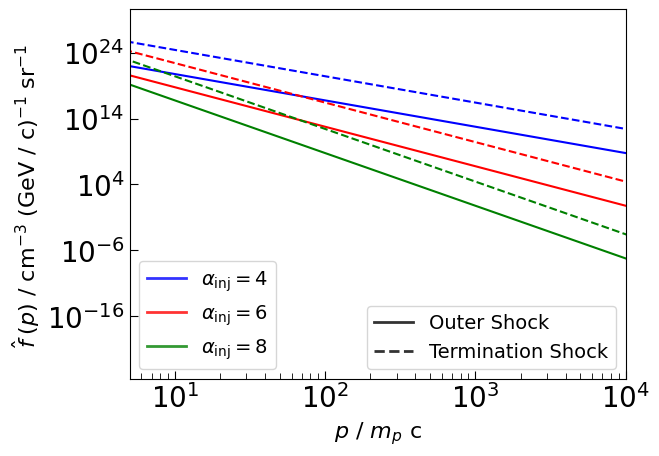

In [26]:
fig, ax = plt.subplots()


for ish, shock in enumerate(shock_types):

    # get average density, velocity, injection index in shock
    dens_shock = np.mean(dens_data[shck_mask_datas[ish] == True])
    vel_shock = np.mean(vel_mag_data[shck_mask_datas[ish] == True])
    print(dens_shock, vel_shock.to(u.km/u.s))

    # indices for np digitize
    kappa10_idx = np.digitize(np.log10(kappa_10.value), log10_kappa10_grid, right=True)
    R0_idx = np.digitize(np.log10(R0.value), log10_R0_grid, right=True)
    vel_idx = np.digitize(np.log10(vel_shock.to_value(u.km/u.s)), log10_vel_grid, right=True)
    dens_idx = np.digitize(np.log10(dens_shock.to_value(u.g/u.cm**3)), log10_dens_grid, right=True)

    for ia, alpha_inj in enumerate(selected_alphas):
        alpha_inj_idx = np.digitize(alpha_inj, alpha_inj_grid, right=True)
        steady_state_spect = steady_state_grid_full[:,alpha_inj_idx,kappa10_idx, R0_idx, vel_idx, dens_idx]

        ax.loglog(10**log10_mom_grid / (const.m_p.cgs * const.c.cgs), steady_state_spect, label=bow_shock_labels[shock], ls=shock_type_ls[ish], color=alpha_inj_colors[ia])

ax.set_xlabel(r"$p$ / $m_p$ c", fontsize=16)
ax.set_ylabel(r"$\hat{f} \; (p)$ / cm$^{-3}$ (GeV / c)$^{-1}$ sr$^{-1}$ ", fontsize=16)

ax.set_xlim(5, 1e4)

ax.tick_params(axis='both', direction="in", which='major', size=6, labelsize=20)
ax.tick_params(axis='both', direction="in", which='minor', size=4, labelsize=16)

leg1 = ax.legend(handles=alpha_inj_handles, loc="lower left", prop={"size":14})
ax.add_artist(leg1)
ax.legend(handles=shck_handles, loc="lower right", prop={"size":14})